# 03 · Trip statistics

**Who Gets a Bluebike?** · CP 101 final project

Load one month of raw Bluebikes trips and measure how far each ride went in a straight line. This notebook uses January 2024 (`data/raw/bluebikes/202401-bluebikes-tripdata.csv`). Run `00_download_trips.ipynb` first so that file exists.

The distance is the straight line between the recorded start and end points, not the path the rider took. Points start as latitude and longitude (EPSG:4326) and are projected to CRS 2249, the same projected coordinate system as notebook 02 (NAD83 / Massachusetts Mainland, in feet). The distance column is that length in feet.

`trips` is only a runtime variable. It is not written to disk. Each row keeps the trip id, the start and end time, the start and end location, and the distance.

In [24]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

RAW_TRIPS = Path("../data/raw/bluebikes")
LOCAL_CRS = 2249  # NAD83 / Massachusetts Mainland, in feet
month_name = 'March'

month = pd.read_csv(
    RAW_TRIPS / "202403-bluebikes-tripdata.csv",
    usecols=["ride_id", "started_at", "ended_at", "start_lat", "start_lng", "end_lat", "end_lng"],
)
month["started_at"] = pd.to_datetime(month["started_at"])
month["ended_at"] = pd.to_datetime(month["ended_at"])

# A trip with no end point has no end location and no distance.
rows_in = len(month)
month = month.dropna(subset=["start_lat", "start_lng", "end_lat", "end_lng"]).copy()
print(f"kept {len(month)} of {rows_in} {month_name} trips")

# lat/lon are degrees (EPSG:4326). Project both ends, then measure the straight line.
start_points = gpd.GeoSeries(
    gpd.points_from_xy(month["start_lng"], month["start_lat"]),
    crs=4326,
).to_crs(LOCAL_CRS)
end_points = gpd.GeoSeries(
    gpd.points_from_xy(month["end_lng"], month["end_lat"]),
    crs=4326,
).to_crs(LOCAL_CRS)
# Assign by position. The point series has its own index, so label alignment would leave gaps.
month["distance"] = start_points.distance(end_points).to_numpy()
del start_points, end_points

# Temporary working table: trip id, times, locations, and distance. Not saved.
trips = month[
    ["ride_id", "started_at", "ended_at", "start_lat", "start_lng", "end_lat", "end_lng", "distance"]
].copy()
del month

trips.head()

kept 261487 of 261687 March trips


,ride_id,started_at,ended_at,start_lat,start_lng,end_lat,end_lng,distance
0,36F2D943CB689742,2024-03-20 08:18:13,2024-03-20 08:28:36,42.352623,-71.055692,42.371848,-71.060292,7115.591821
1,FCEA695AA8EBDECC,2024-03-11 22:45:35,2024-03-11 22:46:46,42.352238,-71.055642,42.352175,-71.055547,34.538913
2,24780C0294088FB4,2024-03-06 06:31:27,2024-03-06 06:46:41,42.352175,-71.055547,42.366420,-71.088542,10318.723307
3,64032901A4475175,2024-03-13 06:34:26,2024-03-13 06:49:15,42.352175,-71.055547,42.366420,-71.088542,10318.723307
4,4D720412FD7A3566,2024-03-31 13:29:10,2024-03-31 13:37:54,42.351907,-71.055861,42.365673,-71.064263,5506.729360


In [25]:
trips['distance_miles'] = trips['distance'] / 5280
greater_than_zero_distance = trips[trips['distance'] > 0]
len(greater_than_zero_distance)

254777

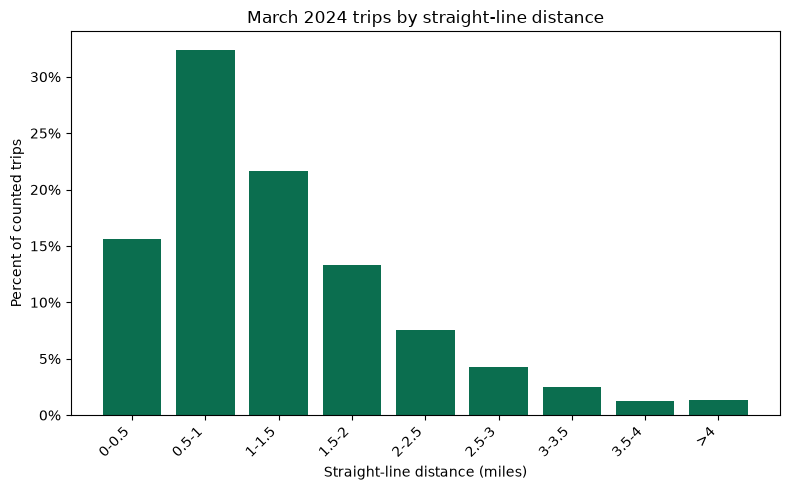

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Half-mile groups from 0 to 4. Trips of 4 miles or more share the last bar.
miles = greater_than_zero_distance["distance_miles"]
half_mile = np.floor(miles.to_numpy() * 2).astype(int)
half_mile = np.clip(half_mile, 0, 8)
labels = ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-2.5", "2.5-3", "3-3.5", "3.5-4", ">4"]
counts = pd.Series(half_mile).value_counts().reindex(range(len(labels)), fill_value=0)
percent = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(labels, percent.to_numpy(), color="#0b6e4f")
ax.set_xlabel("Straight-line distance (miles)")
ax.set_ylabel("Percent of counted trips")
ax.set_title(f"{month_name} 2024 trips by straight-line distance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0f}%"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()